# Laboratório — Redes Neurais Convolucionais (CNN) — Parte II

# Setup

In [1]:
# Importar as bibliotecas utilizadas no notebook

import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Definir sementes para tornar os experimentos mais reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)


# 1. Carregamento e Preparação dos Dados

In [2]:
# Carregar o Fashion-MNIST
#
# Se o arquivo utilizado nos laboratórios anteriores estiver disponível,
# ele será utilizado. Caso contrário, o próprio Keras fará o download do dataset.

if os.path.exists("fashion_mnist.npz"):
    dados = np.load("fashion_mnist.npz")

    X_train = dados["X_train"]
    y_train = dados["y_train"]
    X_test = dados["X_test"]
    y_test = dados["y_test"]

    origem = "arquivo local fashion_mnist.npz"
else:
    (X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
    origem = "keras.datasets.fashion_mnist"

nomes_classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Normalizar os pixels para o intervalo entre 0 e 1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Adicionar explicitamente a dimensão do canal

X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print(f"Origem dos dados: {origem}")
print(f"Treinamento: {X_train.shape}")
print(f"Teste:       {X_test.shape}")
print(f"Classes:     {len(np.unique(y_train))}")
print(f"Shape de uma imagem: {X_train[0].shape}")


Origem dos dados: arquivo local fashion_mnist.npz
Treinamento: (60000, 28, 28, 1)
Teste:       (10000, 28, 28, 1)
Classes:     10
Shape de uma imagem: (28, 28, 1)


## Perguntas

1. Qual é o formato de entrada de uma imagem do Fashion-MNIST nesta CNN?  
2. O que representa o último valor do shape `28 × 28 × 1`?  
3. Qual conceito da Parte I explica por que essa dimensão de canais precisa ser preservada?


# 2. Da Primeira para a Segunda Camada Convolucional

In [3]:
# Construir duas camadas convolucionais consecutivas.
#
# A primeira camada recebe uma imagem com 1 canal e gera 4 mapas.
# A segunda camada recebe esses 4 mapas como seus 4 canais de entrada
# e utiliza 8 filtros.

modelo_encadeamento = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        filters=4,
        kernel_size=(3, 3),
        padding="valid",
        activation="relu",
        name="conv1"
    ),

    layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        padding="valid",
        activation="relu",
        name="conv2"
    )
])

modelo_encadeamento.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 4)      │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 8)      │           296 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 336 (1.31 KB)

 Trainable params: 336 (1.31 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

4. A `conv1` recebe 1 canal e possui 4 filtros. Quantos mapas de características ela gera?  
5. Quantos canais de entrada a `conv2` recebe? De onde surgiram esses canais?  
6. A `conv2` possui 8 filtros. Quantos mapas de características ela gera?  
7. Complete a relação: **quantidade de filtros de uma camada = __________ da saída dessa camada**.


# 3. Profundidade dos Filtros da Segunda Camada

In [4]:
# Inspecionar a forma real dos kernels e biases das duas camadas.
#
# O TensorFlow armazena os kernels de Conv2D no formato:
# (altura_kernel, largura_kernel, canais_entrada, quantidade_filtros)

conv1 = modelo_encadeamento.get_layer("conv1")
conv2 = modelo_encadeamento.get_layer("conv2")

kernel1, bias1 = conv1.get_weights()
kernel2, bias2 = conv2.get_weights()

print("conv1")
print(f"  Shape dos kernels: {kernel1.shape}")
print(f"  Shape dos biases:  {bias1.shape}")
print(f"  Parâmetros:         {conv1.count_params()}")

print("\nconv2")
print(f"  Shape dos kernels: {kernel2.shape}")
print(f"  Shape dos biases:  {bias2.shape}")
print(f"  Parâmetros:         {conv2.count_params()}")

# Cálculo manual da quantidade de parâmetros

parametros_conv1 = ((3 * 3 * 1) + 1) * 4
parametros_conv2 = ((3 * 3 * 4) + 1) * 8

print("\nCálculo manual")
print(f"  conv1: {parametros_conv1}")
print(f"  conv2: {parametros_conv2}")


conv1
  Shape dos kernels: (3, 3, 1, 4)
  Shape dos biases:  (4,)
  Parâmetros:         40

conv2
  Shape dos kernels: (3, 3, 4, 8)
  Shape dos biases:  (8,)
  Parâmetros:         296

Cálculo manual
  conv1: 40
  conv2: 296


## Perguntas

8. Como interpretar o shape `(3, 3, 4, 8)` dos kernels da `conv2`?  
9. Quantas matrizes 3 × 3 existem dentro de **um único filtro** da `conv2`? Por quê?  
10. Por que cada filtro da `conv2` precisa atuar sobre **todos** os mapas produzidos pela `conv1`?  
11. Refaça manualmente o cálculo da quantidade de parâmetros treináveis da `conv2`.  
12. Se a `conv1` gerasse 16 mapas, qual passaria a ser a profundidade de cada filtro da camada seguinte?


# 4. Um Único Valor da Segunda Camada

In [5]:
# Obter as ativações da conv1 e da conv2 para uma única imagem

extrator_encadeamento = keras.Model(
    inputs=modelo_encadeamento.inputs,
    outputs=[
        modelo_encadeamento.get_layer("conv1").output,
        modelo_encadeamento.get_layer("conv2").output
    ]
)

imagem = X_test[0:1]

mapas_conv1, mapas_conv2 = extrator_encadeamento.predict(imagem, verbose=0)

print(f"Entrada original: {imagem.shape}")
print(f"Saída da conv1:   {mapas_conv1.shape}")
print(f"Saída da conv2:   {mapas_conv2.shape}")

# Calcular manualmente a posição [0, 0] do primeiro filtro da conv2.
#
# A região analisada possui:
# 3 linhas × 3 colunas × 4 canais.

regiao = mapas_conv1[0, 0:3, 0:3, :]
pesos_filtro_1 = kernel2[:, :, :, 0]

z_manual = np.sum(regiao * pesos_filtro_1) + bias2[0]
a_manual = max(0.0, z_manual)

a_tensorflow = mapas_conv2[0, 0, 0, 0]

print(f"\nShape da região analisada: {regiao.shape}")
print(f"Shape do primeiro filtro:   {pesos_filtro_1.shape}")
print(f"Z calculado manualmente:    {z_manual:.6f}")
print(f"a = ReLU(Z) manual:         {a_manual:.6f}")
print(f"Saída do TensorFlow:         {a_tensorflow:.6f}")


Entrada original: (1, 28, 28, 1)
Saída da conv1:   (1, 26, 26, 4)
Saída da conv2:   (1, 24, 24, 8)

Shape da região analisada: (3, 3, 4)
Shape do primeiro filtro:   (3, 3, 4)
Z calculado manualmente:    0.000000
a = ReLU(Z) manual:         0.000000
Saída do TensorFlow:         0.000000


## Perguntas

13. Por que a região utilizada no cálculo possui shape `3 × 3 × 4`, e não apenas `3 × 3`?  
14. O cálculo gera quatro valores separados, um para cada canal, ou um único valor final para o filtro? Explique.  
15. Como esse cálculo confirma a ideia de que **cada filtro atua simultaneamente sobre todos os canais da entrada**?


# 5. Efeito do Stride

In [6]:
# Comparar o formato da saída modificando somente o stride.
#
# Em todos os casos:
# - entrada = 28 × 28 × 1
# - kernel = 3 × 3
# - filtros = 8
# - padding = "valid"

entrada_exemplo = tf.zeros((1, 28, 28, 1))

conv_stride_1 = layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding="valid"
)

conv_stride_2 = layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    strides=(2, 2),
    padding="valid"
)

saida_stride_1 = conv_stride_1(entrada_exemplo)
saida_stride_2 = conv_stride_2(entrada_exemplo)

print(f"Entrada:                  {tuple(entrada_exemplo.shape)}")
print(f"Stride 1 -> saída:        {tuple(saida_stride_1.shape)}")
print(f"Stride 2 -> saída:        {tuple(saida_stride_2.shape)}")


Entrada:                  (1, 28, 28, 1)
Stride 1 -> saída:        (1, 26, 26, 8)
Stride 2 -> saída:        (1, 13, 13, 8)


## Perguntas

16. O que o hiperparâmetro **stride** controla durante a varredura do filtro?  
17. O que aconteceu com a altura e a largura da saída quando o stride passou de 1 para 2?  
18. A alteração do stride mudou a quantidade de filtros da camada? Como isso aparece no shape da saída?


# 6. Efeito do Padding

In [7]:
# Comparar padding="valid" e padding="same".
#
# Agora o stride é mantido em 1 para isolar o efeito do padding.

conv_valid = layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding="valid"
)

conv_same = layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding="same"
)

saida_valid = conv_valid(entrada_exemplo)
saida_same = conv_same(entrada_exemplo)

print(f"Entrada:                   {tuple(entrada_exemplo.shape)}")
print(f'padding="valid" -> saída: {tuple(saida_valid.shape)}')
print(f'padding="same"  -> saída: {tuple(saida_same.shape)}')


Entrada:                   (1, 28, 28, 1)
padding="valid" -> saída: (1, 26, 26, 8)
padding="same"  -> saída: (1, 28, 28, 8)


## Perguntas

19. Qual foi a diferença entre as dimensões espaciais das saídas com `padding="valid"` e `padding="same"`?  
20. Qual é a função do padding no processamento das regiões próximas às bordas?  
21. Considerando `stride=1`, qual configuração preservou altura e largura da entrada?


# 7. Stride e Padding em Conjunto

In [8]:
# Comparar três configurações mantendo kernel 3 × 3 e 8 filtros.

configuracoes = [
    ("stride 1 | valid", (1, 1), "valid"),
    ("stride 1 | same",  (1, 1), "same"),
    ("stride 2 | same",  (2, 2), "same")
]

for descricao, strides, padding in configuracoes:
    camada = layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=strides,
        padding=padding
    )

    saida = camada(entrada_exemplo)

    print(f"{descricao:20s} -> {tuple(saida.shape)}")


stride 1 | valid     -> (1, 26, 26, 8)
stride 1 | same      -> (1, 28, 28, 8)
stride 2 | same      -> (1, 14, 14, 8)


## Perguntas

22. Entre as três configurações, qual preservou as dimensões espaciais `28 × 28`?  
23. Por que `padding="same"` não impede a redução espacial quando utilizamos `stride=2`?  
24. Stride e padding são parâmetros aprendidos pela rede ou hiperparâmetros definidos na arquitetura?


# 8. Pooling

In [9]:
# Primeiro, observar o Max Pooling em uma matriz pequena.

matriz_exemplo = np.array([
    [1, 3, 2, 0],
    [4, 6, 5, 1],
    [2, 1, 7, 3],
    [0, 2, 4, 8]
], dtype="float32")

entrada_pool = matriz_exemplo.reshape(1, 4, 4, 1)

pool = layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(2, 2)
)

saida_pool = pool(entrada_pool).numpy()[0, :, :, 0]

print("Entrada 4 × 4:")
print(matriz_exemplo)

print("\nApós MaxPooling 2 × 2:")
print(saida_pool)

print(f"\nParâmetros treináveis do pooling: {pool.count_params()}")


Entrada 4 × 4:
[[1. 3. 2. 0.]
 [4. 6. 5. 1.]
 [2. 1. 7. 3.]
 [0. 2. 4. 8.]]

Após MaxPooling 2 × 2:
[[6. 5.]
 [2. 8.]]

Parâmetros treináveis do pooling: 0


## Perguntas

25. Como cada valor da matriz `2 × 2` de saída foi obtido?  
26. O Max Pooling possui pesos ou biases treináveis?  
27. Qual dimensão foi reduzida pelo pooling: profundidade, dimensões espaciais ou ambas?


Antes do pooling: (1, 26, 26, 4)
Depois do pooling: (1, 13, 13, 4)


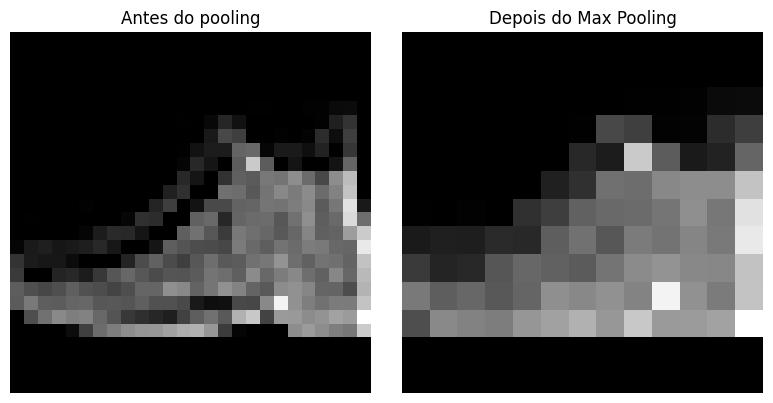

In [10]:
# Aplicar Max Pooling aos mapas produzidos pela primeira convolução.

pool_feature_maps = layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(2, 2)
)

mapas_apos_pooling = pool_feature_maps(mapas_conv1).numpy()

print(f"Antes do pooling: {mapas_conv1.shape}")
print(f"Depois do pooling: {mapas_apos_pooling.shape}")

# Visualizar um mesmo mapa antes e depois do pooling

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(mapas_conv1[0, :, :, 0], cmap="gray")
plt.title("Antes do pooling")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mapas_apos_pooling[0, :, :, 0], cmap="gray")
plt.title("Depois do Max Pooling")
plt.axis("off")

plt.tight_layout()
plt.show()


## Perguntas

28. Quantos mapas de características existiam antes e depois do pooling?  
29. O pooling alterou a quantidade de canais?  
30. Qual é o principal efeito do pooling sobre as dimensões dos mapas de características?


# 9. Da Parte Convolucional para as Camadas Densas

In [11]:
# Construir uma CNN completa para classificação do Fashion-MNIST.
#
# A arquitetura terá:
# Conv2D -> MaxPooling -> Conv2D -> MaxPooling -> Flatten -> Dense -> Dense

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="conv1_full"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool1"
    ),

    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="conv2_full"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool2"
    ),

    # Transformar os mapas de características em um vetor
    layers.Flatten(name="flatten"),

    # Camada densa oculta
    layers.Dense(
        units=32,
        activation="relu",
        name="dense1"
    ),

    # Camada de saída: 10 classes
    layers.Dense(
        units=10,
        activation="softmax",
        name="saida"
    )
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_full (Conv2D)             │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_full (Conv2D)             │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,698 (104.29 KB)

 Trainable params: 26,698 (104.29 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

31. Qual é a função do `Flatten` entre a parte convolucional e as camadas densas?  
32. O `Flatten` possui parâmetros treináveis?  
33. Após o segundo pooling, o tensor possui shape `7 × 7 × 16`. Quantos valores serão entregues pelo `Flatten` à primeira camada Dense?  
34. Por que a camada de saída possui 10 neurônios e utiliza Softmax?  
35. Na arquitetura acima, identifique hiperparâmetros associados às **camadas convolucionais**, ao **pooling** e às **camadas densas**.


# 10. Parâmetros Treináveis da CNN Completa

In [12]:
# Inspecionar os parâmetros treináveis de cada camada.

for camada in model.layers:
    print(
        f"{camada.name:12s} | "
        f"{camada.__class__.__name__:18s} | "
        f"parâmetros = {camada.count_params()}"
    )

# Cálculos manuais

params_conv1 = ((3 * 3 * 1) + 1) * 8
params_conv2 = ((3 * 3 * 8) + 1) * 16

# Após o segundo pooling:
# 7 × 7 × 16 = 784 entradas para a Dense de 32 neurônios

params_dense1 = (784 + 1) * 32
params_saida = (32 + 1) * 10

print("\nCálculo manual:")
print(f"conv1_full: {params_conv1}")
print(f"conv2_full: {params_conv2}")
print(f"dense1:     {params_dense1}")
print(f"saida:      {params_saida}")
print(f"TOTAL:      {params_conv1 + params_conv2 + params_dense1 + params_saida}")


conv1_full   | Conv2D             | parâmetros = 80
pool1        | MaxPooling2D       | parâmetros = 0
conv2_full   | Conv2D             | parâmetros = 1168
pool2        | MaxPooling2D       | parâmetros = 0
flatten      | Flatten            | parâmetros = 0
dense1       | Dense              | parâmetros = 25120
saida        | Dense              | parâmetros = 330

Cálculo manual:
conv1_full: 80
conv2_full: 1168
dense1:     25120
saida:      330
TOTAL:      26698


## Perguntas

36. Por que a `conv2_full` possui mais parâmetros que a `conv1_full`, mesmo usando o mesmo kernel `3 × 3`?  
37. Por que `MaxPooling2D` e `Flatten` aparecem com zero parâmetros treináveis?  
38. Quais são os **parâmetros aprendidos** nas camadas `Conv2D` e nas camadas `Dense`?  
39. Explique por que **quantidade de filtros**, **tamanho do kernel**, **stride**, **padding**, **pool size**, **quantidade de camadas densas** e **neurônios por camada densa** são hiperparâmetros, e não parâmetros aprendidos.


# 11. Treinamento da CNN

In [13]:
# Configurar o treinamento.
#
# Os hiperparâmetros de treinamento estudados anteriormente continuam presentes
# em uma CNN: loss, optimizer, learning rate, batch size e epochs.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

historico = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 60ms/step - accuracy: 0.7371 - loss: 0.7448 - val_accuracy: 0.8177 - val_loss: 0.4996
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.8349 - loss: 0.4577 - val_accuracy: 0.8503 - val_loss: 0.4257
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.8576 - loss: 0.3979 - val_accuracy: 0.8658 - val_loss: 0.3807
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.8692 - loss: 0.3650 - val_accuracy: 0.8738 - val_loss: 0.3551
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 71ms/step - accuracy: 0.8771 - loss: 0.3434 - val_accuracy: 0.8772 - val_loss: 0.3409


## Perguntas

40. Cite cinco hiperparâmetros de treinamento utilizados nessa célula.  
41. Esses hiperparâmetros são exclusivos de CNNs ou já apareciam no treinamento das MLPs?  
42. Durante o treinamento, quais elementos da CNN são efetivamente ajustados pelo otimizador?


# 12. Avaliação

Loss no teste:     0.3587
Acurácia no teste: 0.8721


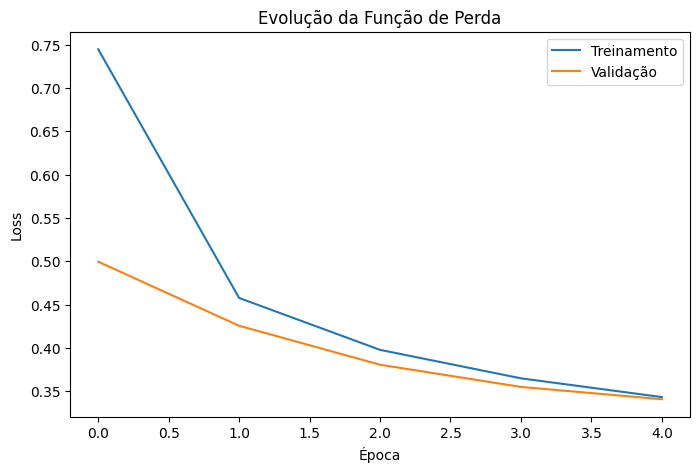

In [14]:
# Avaliar a CNN no conjunto de teste

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Loss no teste:     {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")

# Visualizar a evolução da função de perda

plt.figure(figsize=(8, 5))
plt.plot(historico.history["loss"], label="Treinamento")
plt.plot(historico.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda")
plt.legend()
plt.show()


## Perguntas

43. Qual é a diferença entre a loss de treinamento e a loss de validação apresentadas no gráfico?  
44. A acurácia de teste, isoladamente, permite afirmar que um determinado hiperparâmetro foi responsável pelo desempenho obtido? Por quê?


# 13. A Evolução dos Mapas ao Longo da CNN

Entrada:      (1, 28, 28, 1)
conv1_full:   (1, 28, 28, 8)
pool1:        (1, 14, 14, 8)
conv2_full:   (1, 14, 14, 16)
pool2:        (1, 7, 7, 16)


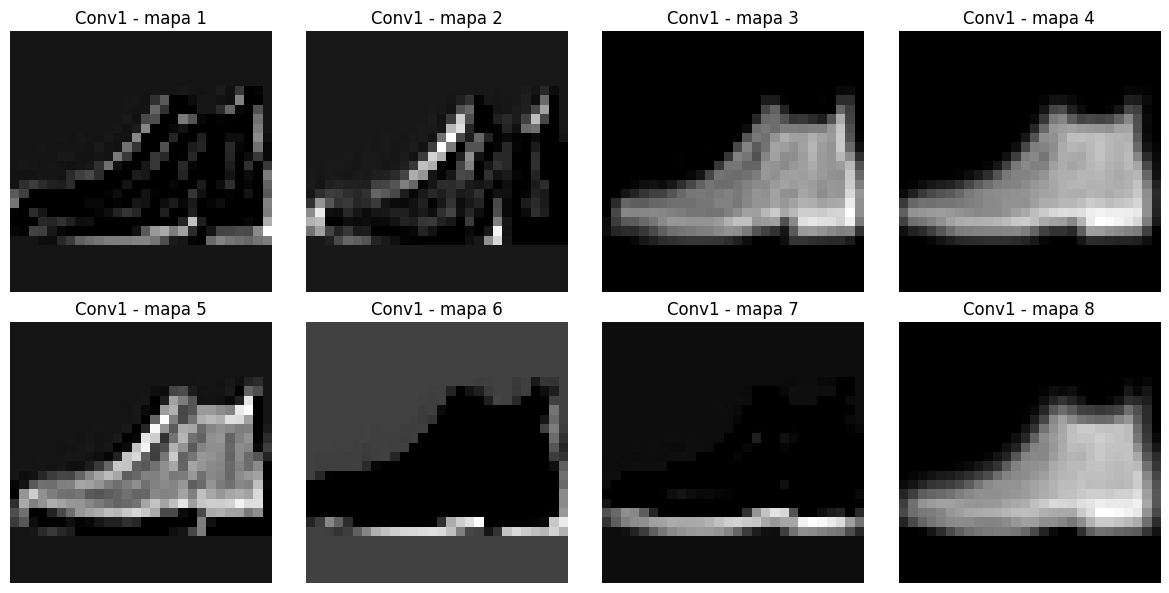

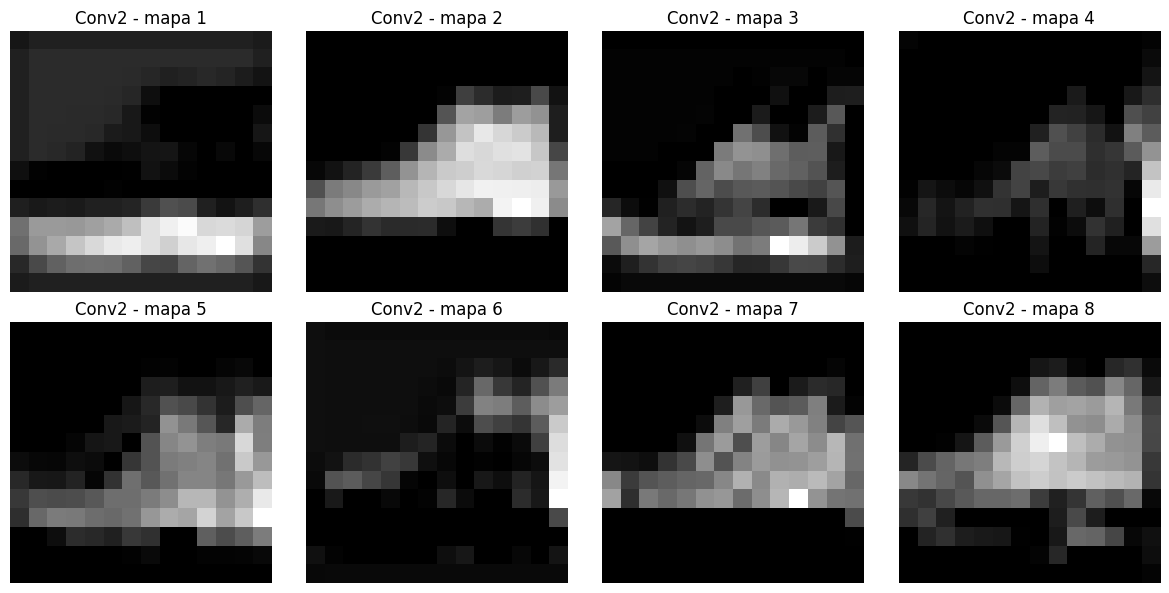

In [15]:
# Criar um modelo auxiliar para observar as ativações internas
# após o treinamento.

extrator = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer("conv1_full").output,
        model.get_layer("pool1").output,
        model.get_layer("conv2_full").output,
        model.get_layer("pool2").output
    ]
)

imagem = X_test[0:1]

saida_conv1, saida_pool1, saida_conv2, saida_pool2 = extrator.predict(
    imagem,
    verbose=0
)

print(f"Entrada:      {imagem.shape}")
print(f"conv1_full:   {saida_conv1.shape}")
print(f"pool1:        {saida_pool1.shape}")
print(f"conv2_full:   {saida_conv2.shape}")
print(f"pool2:        {saida_pool2.shape}")

# Visualizar os 8 mapas da primeira camada convolucional

plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(saida_conv1[0, :, :, i], cmap="gray")
    plt.title(f"Conv1 - mapa {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Visualizar os 8 primeiros mapas da segunda camada convolucional

plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(saida_conv2[0, :, :, i], cmap="gray")
    plt.title(f"Conv2 - mapa {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Perguntas

45. Observe os shapes impressos. Em quais pontos a profundidade aumentou? O que provocou esse aumento?  
46. Em quais pontos as dimensões espaciais diminuíram? O que provocou essa redução?  
47. Explique o fluxo completo entre `conv1_full` e `conv2_full`: como os mapas produzidos pela primeira camada são utilizados pela segunda?
